In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]
# sex-iig 0/1, embarked-iig one-hot bolgono
df["sex"] = (df["sex"] == "male").astype(int)
df = pd.get_dummies(df, columns=["embarked"], dtype=int)

X, y = df.drop(columns="survived"), df["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (712, 9) | test: (179, 9)


In [ ]:
# age-iin hooson utgiig train-ii median-aar nuhuj baigaad scale hiihed 
model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVC())

params = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.05, 0.1, 0.5]}
grid = GridSearchCV(model, params, cv=5)
grid.fit(X_train, y_train)
print("Best ni :", grid.best_params_, "| CV:", round(grid.best_score_, 4))

хамгийн сайн: {'svc__C': 10, 'svc__gamma': 0.05} | CV: 0.8329


Тестийн нарийвчлал: 0.8212
              precision    recall  f1-score   support

  нас барсан     0.8000    0.9455    0.8667       110
 амьд үлдсэн     0.8776    0.6232    0.7288        69

    accuracy                         0.8212       179
   macro avg     0.8388    0.7843    0.7977       179
weighted avg     0.8299    0.8212    0.8135       179



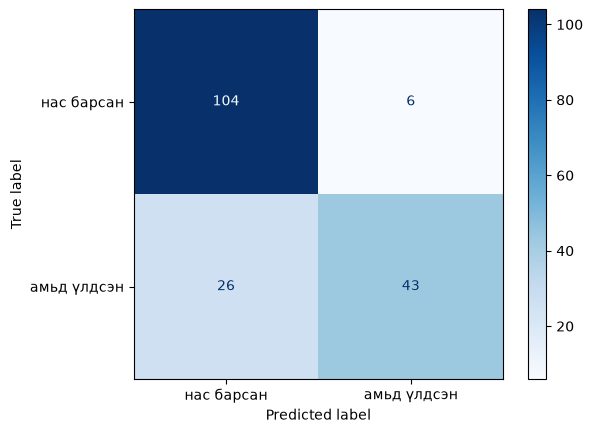

In [ ]:
# test deer shalgah
y_pred = grid.predict(X_test)
names = ["нас барсан", "амьд үлдсэн"]

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=names, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=names, cmap="Blues")
plt.show()